# 06 Evaluation: costly errors with RGB and 13 bands

**Purpose.** Compare all three models (random forest, CNN, ResNet18) on RGB and 13 bands with the same test patches, and answer the sub-questions: does the 13-band advantage hold for every model (SQ1), which confusions are costly for a crop insurer and how often each model makes them (SQ2), and do the 13 bands reduce them (SQ3). Nothing is trained here: the notebook reads the saved test predictions of notebooks 03 to 05.

**Functions.** `src/piece_of_crop/evaluate.py` (`insurer_cost_matrix`, `listed_critical_confusions`, `load_predictions`, `block_bootstrap_ci`) and `data.py` (`read_split`, `get_cache`, `to_rgb_image`).

**Reads.** `results/split.csv`, `results/insurer_cost_matrix.csv`, the 18 prediction files in `results/predictions/` (3 models x 2 inputs x 3 seeds) and the patch cache `data/eurosat_cache.npy` for the images in section 8.

**Saves.** `results/evaluation_runs.csv`, `evaluation_per_class.csv`, `evaluation_differences.csv`, `evaluation_confused_pairs.csv`, `evaluation_sensitivity.csv`, `evaluation_review.csv` and the figures `results/figures/evaluation_*.png`.

## 1. Setup and the saved predictions

Every prediction file must contain the 3,854 test patches of `split.csv` in the same order and with the same labels. This makes the comparison paired: RGB and 13 bands, and the three models, are judged on exactly the same patches, so a difference between them cannot come from easier or harder test patches.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from IPython.display import display

from piece_of_crop import BAND_NAMES, CLASS_NAMES, MODEL_FILES, read_split, get_cache, to_rgb_image
from piece_of_crop import insurer_cost_matrix, listed_critical_confusions, load_predictions, block_bootstrap_ci

SEEDS = (0, 1, 2)
INPUTS = ("rgb", "13band")
MODELS = tuple(MODEL_FILES)  # RandomForest, SmallCNN, ResNet18
N_BOOTSTRAP = 2000
BOOTSTRAP_SEED = 0

project_root = Path.cwd().parents[0]
data_dir = project_root / "data" / "EuroSAT_MS"
results_dir = project_root / "results"
figures_dir = results_dir / "figures"
predictions_dir = results_dir / "predictions"

split = read_split(results_dir / "split.csv")
test_rows = split[split["split"].eq("test")].reset_index(drop=True)
predictions = load_predictions(predictions_dir, test_rows, SEEDS)
y_true = test_rows["label"].to_numpy()
blocks = test_rows["block"].to_numpy()
label_ids = np.arange(len(CLASS_NAMES))

print("Prediction files:", len(predictions))
print("Test patches:", len(test_rows), "in", test_rows["block"].nunique(), "spatial blocks")

Prediction files: 18
Test patches: 3854 in 134 spatial blocks


## 2. The insurer cost matrix

A crop insurer checks whether a parcel is the land use its owner declared before pricing a policy or paying a claim. Not every mistake of a model costs the same in that check, so we weigh each confusion with a cost, in severity points: rows are the true class, columns the predicted class, and the expected cost of a model is the average over its predictions. This is the loss matrix of decision theory, where "the consequences of these two types of mistake can be dramatically different" (Bishop, *Pattern Recognition and Machine Learning*, section 1.5.2, page 41).

| Cost | Confusion | Why it matters to an insurer |
|---|---|---|
| 9 | agricultural land (AnnualCrop, PermanentCrop, Pasture, HerbaceousVegetation) with Forest or built-up land (Highway, Industrial, Residential) | the basic use of the parcel is wrong: the insurer would cover land that is not farmed, or turn away farmland |
| 8 | a crop class (AnnualCrop, PermanentCrop) with another agricultural class | the land is farmed, but the insured crop is wrong, and orchards, cereals and grazing land carry different risks and premiums |
| 6 | Pasture with HerbaceousVegetation | both are grassland, so the risk differs less, but managed grazing land is insured differently from natural grass |
| 2 | every other mistake (for example River with Highway) | wrong, but outside agricultural insurance |

We call the confusions with a cost of 8 or 9 **critical**: they involve farmland and change either whether the parcel is farmed or what grows on it.

**When the weights were set.** Our plan was to write the costs down before training. The matrix was first committed on 22 November 2026, together with results from an earlier split that we later replaced. It was therefore fixed before all results in this notebook, which come from the restored split (notebooks 03 to 05, 24 to 26 November), and we do not change any weight now. The cell below checks that the matrix in `src/` is still the committed table.

**Counterargument.** The points are not euros and do not come from insurance data; another insurer could weigh the confusions differently. We accept this. Section 7 tests whether the conclusions change with other weights, including the earlier list of critical confusions, which left out HerbaceousVegetation confused with Forest or built-up land.

In [2]:
costs = insurer_cost_matrix()
critical = costs >= 8
committed = pd.read_csv(results_dir / "insurer_cost_matrix.csv", index_col=0)
assert np.array_equal(committed.to_numpy(), costs), "the cost matrix differs from the committed table"

display(pd.DataFrame(costs, index=CLASS_NAMES, columns=CLASS_NAMES).astype(int))
print("Critical confusions (cost 8 or 9):", int(critical.sum()), "of 90 possible mistakes")

,AnnualCrop,Forest,HerbaceousVegetation,Highway,Industrial,Pasture,PermanentCrop,Residential,River,SeaLake
AnnualCrop,0,9,8,9,9,8,8,9,2,2
Forest,9,0,9,2,2,9,9,2,2,2
HerbaceousVegetation,8,9,0,9,9,6,8,9,2,2
Highway,9,2,9,0,2,9,9,2,2,2
Industrial,9,2,9,2,0,9,9,2,2,2
Pasture,8,9,6,9,9,0,8,9,2,2
PermanentCrop,8,9,8,9,9,8,0,9,2,2
Residential,9,2,9,2,2,9,9,0,2,2
River,2,2,2,2,2,2,2,2,0,2
SeaLake,2,2,2,2,2,2,2,2,2,0


Critical confusions (cost 8 or 9): 42 of 90 possible mistakes


## 3. All models and both inputs on the test set

For every run: accuracy, macro-F1, the share of test patches with a critical error, and the average cost per test patch. Macro-F1 averages the F1 score of the 10 classes with equal weight, so a weak class counts as much as a strong one (F1: lecture_2_introduction_to_ML.pdf, slide 34; the macro average is the "macro avg" row of the classification reports in ImageClassificationML.pdf, page 15). The table shows the mean and standard deviation over the three seeds.

In [3]:
run_rows, class_rows = [], []
for (model, input_type, seed), table in predictions.items():
    y_pred = table["y_pred"].to_numpy()
    run_rows.append({"model": model, "input": input_type, "seed": seed,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "critical_error_rate": critical[y_true, y_pred].mean(),
        "cost_per_patch": costs[y_true, y_pred].mean()})
    for class_id, f1 in zip(label_ids, f1_score(y_true, y_pred, average=None, labels=label_ids)):
        class_rows.append({"model": model, "input": input_type, "seed": seed, "class": CLASS_NAMES[class_id], "f1": f1})

runs = pd.DataFrame(run_rows)
per_class = pd.DataFrame(class_rows)
runs.to_csv(results_dir / "evaluation_runs.csv", index=False)
per_class.to_csv(results_dir / "evaluation_per_class.csv", index=False)

comparison = runs.groupby(["model", "input"], sort=False)[["accuracy", "macro_f1", "critical_error_rate", "cost_per_patch"]]
display(comparison.agg(["mean", "std"]).round(4))

print("F1 per class, mean over the seeds:")
display(per_class.groupby(["class", "model", "input"], sort=False)["f1"].mean().unstack(["model", "input"]).round(3))

accuracy         macro_f1         critical_error_rate  \
                        mean     std     mean     std                mean   
model        input                                                          
RandomForest rgb      0.6985  0.0029   0.6822  0.0026              0.1643   
             13band   0.8567  0.0028   0.8495  0.0030              0.0968   
SmallCNN     rgb      0.9177  0.0017   0.9157  0.0016              0.0503   
             13band   0.9539  0.0035   0.9525  0.0034              0.0349   
ResNet18     rgb      0.9719  0.0020   0.9713  0.0020              0.0239   
             13band   0.9718  0.0019   0.9712  0.0019              0.0247   

                            cost_per_patch          
                        std           mean     std  
model        input                                  
RandomForest rgb     0.0042         1.7234  0.0309  
             13band  0.0017         0.9401  0.0192  
SmallCNN     rgb     0.0026         0.4883  0.0213  
             13band  0.0044         0.3148  0.0338  
ResNet18     rgb     0.0004         0.2083  0.0078  
             13band  0.0015         0.2158  0.0134

F1 per class, mean over the seeds:


model                RandomForest        SmallCNN        ResNet18       
input                         rgb 13band      rgb 13band      rgb 13band
class                                                                   
AnnualCrop                  0.795  0.889    0.949  0.967    0.978  0.980
Forest                      0.898  0.961    0.962  0.977    0.995  0.978
HerbaceousVegetation        0.385  0.725    0.784  0.888    0.906  0.912
Highway                     0.413  0.671    0.909  0.943    0.991  0.990
Industrial                  0.867  0.921    0.948  0.968    0.994  0.994
Pasture                     0.736  0.848    0.944  0.963    0.978  0.974
PermanentCrop               0.490  0.692    0.805  0.854    0.883  0.894
Residential                 0.708  0.880    0.985  0.988    0.996  0.997
River                       0.623  0.915    0.887  0.980    0.993  0.995
SeaLake                     0.907  0.993    0.985  0.997    0.998  0.999

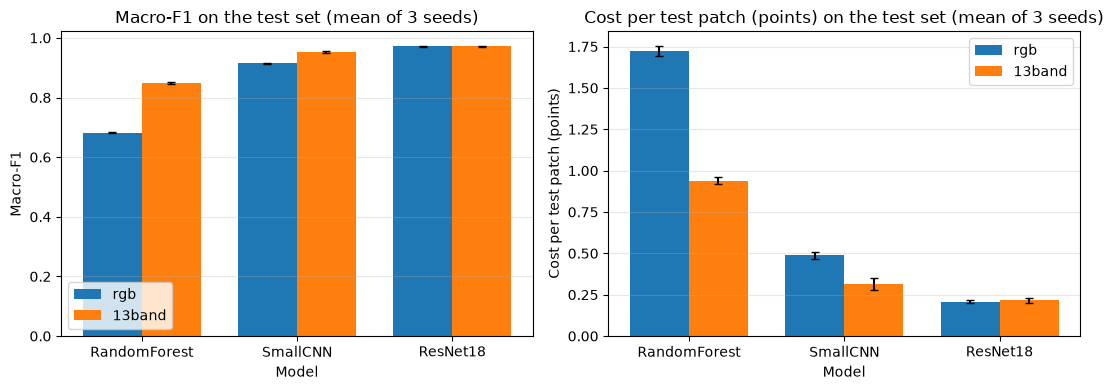

In [4]:
# main comparison figure: macro-F1 and cost per patch
summary = runs.groupby(["model", "input"], sort=False)[["macro_f1", "cost_per_patch"]].agg(["mean", "std"])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
x = np.arange(len(MODELS))
for ax, metric, label in ((axes[0], "macro_f1", "Macro-F1"), (axes[1], "cost_per_patch", "Cost per test patch (points)")):
    for k, input_type in enumerate(INPUTS):
        means = [summary.loc[(m, input_type), (metric, "mean")] for m in MODELS]
        stds = [summary.loc[(m, input_type), (metric, "std")] for m in MODELS]
        ax.bar(x + (k - 0.5) * 0.38, means, width=0.38, yerr=stds, capsize=3, label=input_type)
    ax.set_xticks(x, MODELS)
    ax.set(title=f"{label} on the test set (mean of 3 seeds)", xlabel="Model", ylabel=label)
    ax.grid(alpha=0.3, axis="y")
    ax.legend()
fig.tight_layout()
fig.savefig(figures_dir / "evaluation_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

**Claim.** The 13 bands improve the random forest and the CNN on every measure, and make no difference for the ResNet. The better the model, the larger the share of its remaining mistakes that are costly to an insurer.

**Reasons.** The extra bands add information the RGB patch does not have. The random forest, which only sees band statistics, gains most; the CNN, which also sees shapes and textures, gains less; and the ResNet reaches the same score with RGB alone (notebook 05). The mistakes that are left after a model has learned the easy classes are those between agricultural classes that look alike, and these are exactly the costly ones.

**Evidence.** Test accuracy (mean of three seeds) rises from 69.9% to 85.7% for the random forest and from 91.8% to 95.4% for the CNN, and stays at 97.2% for the ResNet. The share of test patches with a critical error falls from 16.4% to 9.7% (random forest) and from 5.0% to 3.5% (CNN), and is 2.4% against 2.5% for the ResNet. The cost per test patch falls from 1.72 to 0.94 and from 0.49 to 0.31 points, and is 0.21 against 0.22 for the ResNet. Critical mistakes make up 55% of all mistakes of the RGB random forest, 61% of the RGB CNN and 85% of the RGB ResNet (68%, 76% and 88% with 13 bands). Per class, HerbaceousVegetation gains most from the 13 bands for the random forest (F1 0.39 to 0.73) and the CNN (0.78 to 0.89), and River for both (0.62 to 0.92 and 0.89 to 0.98); for the ResNet, Forest drops from 0.995 to 0.978.

**Warrant.** All 18 runs are judged on the same 3,854 test patches, which were never used for training or for choosing a model (lecture_2_introduction_to_ML.pdf, slide 24), so the differences come from the models and inputs. Because the costly mistakes become a larger share as accuracy rises, accuracy alone understates what is left for an insurer to worry about: the best model still makes about 92 critical mistakes per 3,854 patches.

**Counterargument.** The standard deviations over three seeds only show how much training varies. Whether the differences are larger than the uncertainty from the test patches themselves is what section 5 tests.

## 4. Confusion matrices

One matrix per model and input, summed over the three seeds and divided by the number of patches of each true class, so each row shows where the patches of that class went (lecture_2_introduction_to_ML.pdf, slide 35). The diagonal is the recall of each class. Cells with a critical confusion are framed in red.

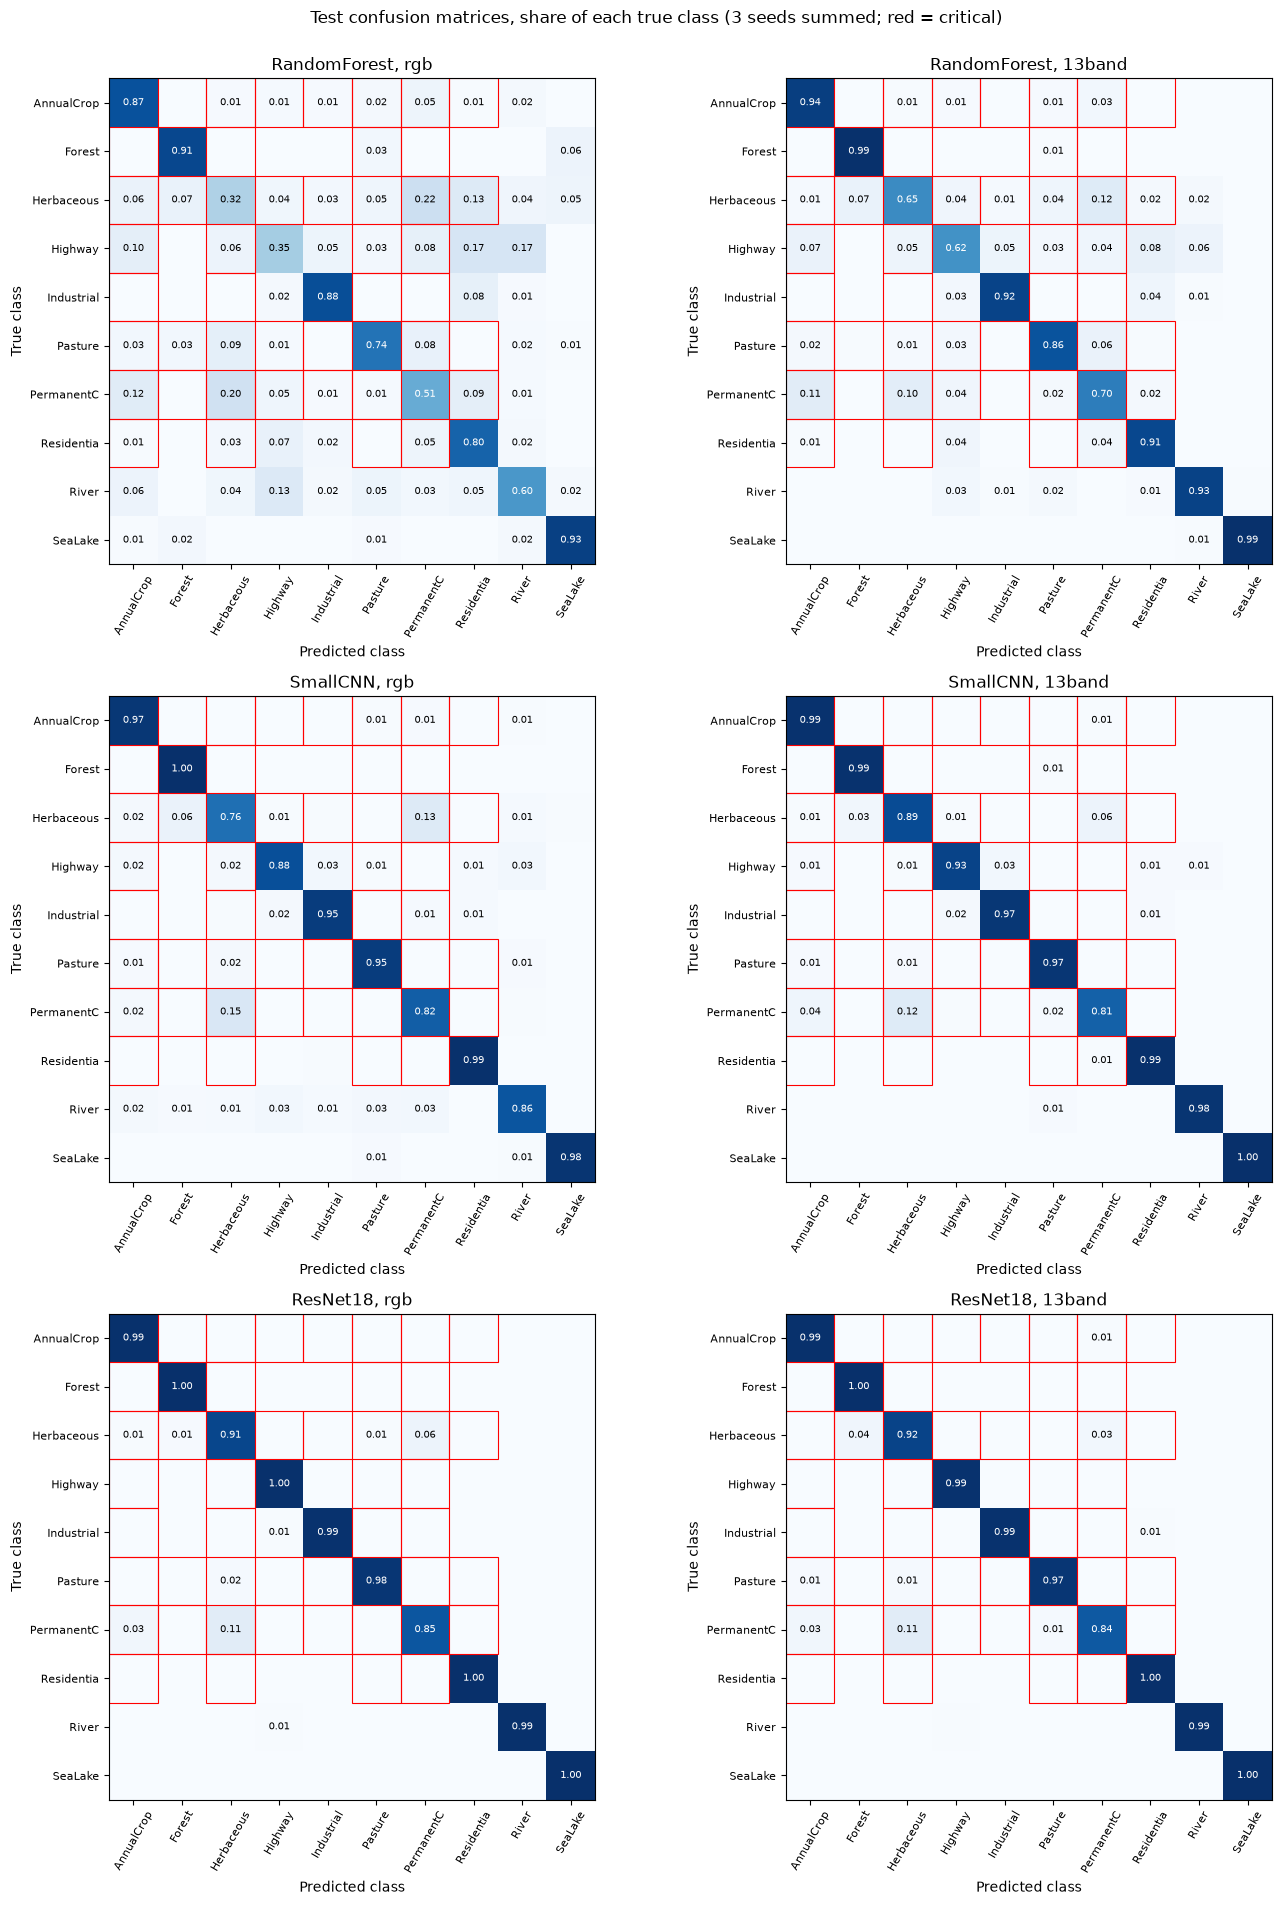

In [5]:
fig, axes = plt.subplots(3, 2, figsize=(14, 19))
short = [name[:10] for name in CLASS_NAMES]
for row, model in enumerate(MODELS):
    for col, input_type in enumerate(INPUTS):
        counts = sum(confusion_matrix(y_true, predictions[(model, input_type, s)]["y_pred"], labels=label_ids) for s in SEEDS)
        rates = counts / counts.sum(axis=1, keepdims=True)
        ax = axes[row, col]
        ax.imshow(rates, cmap="Blues", vmin=0, vmax=1)
        for i in label_ids:
            for j in label_ids:
                if rates[i, j] >= 0.005:
                    ax.text(j, i, f"{rates[i, j]:.2f}", ha="center", va="center", fontsize=7,
                            color="white" if rates[i, j] > 0.5 else "black")
                if critical[i, j]:
                    ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor="red", lw=0.8))
        ax.set_xticks(label_ids, short, rotation=60, fontsize=8)
        ax.set_yticks(label_ids, short, fontsize=8)
        ax.set(title=f"{model}, {input_type}", xlabel="Predicted class", ylabel="True class")
fig.suptitle("Test confusion matrices, share of each true class (3 seeds summed; red = critical)", y=1.0)
fig.tight_layout()
fig.savefig(figures_dir / "evaluation_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

**Claim.** For every model, the mistakes concentrate in the same few critical cells: PermanentCrop and HerbaceousVegetation confused with each other, PermanentCrop called AnnualCrop, and HerbaceousVegetation called Forest.

**Evidence.** The ResNet recognises 85% (RGB) and 84% (13 bands) of the PermanentCrop patches and sends 11% of them to HerbaceousVegetation with both inputs. With 13 bands, 4% of HerbaceousVegetation goes to Forest, against 1% with RGB. For the CNN, the 13 bands halve HerbaceousVegetation called PermanentCrop (13% to 6% of the class). The RGB random forest recognises only 32% of HerbaceousVegetation and spreads the rest over almost every class.

**Warrant.** The diagonal of a row-normalised confusion matrix is the recall of each class, and the off-diagonal cells show where the missing share went (lecture_2_introduction_to_ML.pdf, slide 35). Red cells with values show costly mistakes, so the figure shows directly which confusions the insurer would see.

**Counterargument.** The three seeds are summed, so the figure does not show how much the cells vary between seeds; the table in section 6 gives the counts per seed.

## 5. 13 bands minus RGB, with intervals

For every model and test patch we take the 13-band result minus the RGB result, averaged over the three seeds, for three measures: correct or not (accuracy), critical error or not, and cost. A positive accuracy difference and negative critical-error and cost differences favour the 13 bands.

**Why a block bootstrap.** The three seeds show how much training varies, but not how much the result depends on which test patches we happen to have. A bootstrap estimates this by drawing the test set again many times with replacement and recomputing the mean (external: Efron and Tibshirani, 1993, *An Introduction to the Bootstrap*, chapters 6 and 13). Neighbouring patches in one 0.5° block share fields, weather and season, so they are not independent; we therefore draw whole blocks, as for clustered data (external: Field and Welsh, 2007, "Bootstrapping clustered data", *Journal of the Royal Statistical Society B*, 69(3)). The 2.5th and 97.5th percentiles of 2,000 redrawn means give a 95% interval. If it does not contain 0, the difference is unlikely to be an accident of this test set.

In [6]:
rng = np.random.default_rng(BOOTSTRAP_SEED)
measures = {"accuracy": lambda p: (p == y_true).astype(float),
            "critical_error_rate": lambda p: critical[y_true, p].astype(float),
            "cost_per_patch": lambda p: costs[y_true, p]}

difference_rows = []
for model in MODELS:
    for measure, per_patch in measures.items():
        per_seed = np.array([per_patch(predictions[(model, "13band", s)]["y_pred"].to_numpy())
                             - per_patch(predictions[(model, "rgb", s)]["y_pred"].to_numpy()) for s in SEEDS])
        low, high = block_bootstrap_ci(per_seed.mean(axis=0), blocks, N_BOOTSTRAP, rng)
        difference_rows.append({"model": model, "measure": measure, "13band_minus_rgb": per_seed.mean(),
                                "seed_std": per_seed.mean(axis=1).std(ddof=1), "ci_low": low, "ci_high": high,
                                "excludes_0": not (low <= 0 <= high)})

differences = pd.DataFrame(difference_rows)
differences.to_csv(results_dir / "evaluation_differences.csv", index=False)
display(differences.round(4))

,model,measure,13band_minus_rgb,seed_std,ci_low,ci_high,excludes_0
0,RandomForest,accuracy,0.1582,0.0008,0.1207,0.1992,True
1,RandomForest,critical_error_rate,-0.0675,0.0029,-0.1040,-0.0350,True
2,RandomForest,cost_per_patch,-0.7833,0.0174,-1.1077,-0.5056,True
3,SmallCNN,accuracy,0.0362,0.0052,0.0198,0.0586,True
4,SmallCNN,critical_error_rate,-0.0154,0.0069,-0.0324,-0.0019,True
5,SmallCNN,cost_per_patch,-0.1735,0.0547,-0.3456,-0.0627,True
6,ResNet18,accuracy,-0.0001,0.0007,-0.0066,0.0055,False
7,ResNet18,critical_error_rate,0.0009,0.0010,-0.0051,0.0073,False
8,ResNet18,cost_per_patch,0.0075,0.0071,-0.0431,0.0719,False


**Claim.** The 13-band advantage is real for the random forest and the CNN, and there is no difference for the ResNet, on accuracy, critical errors and cost alike. This answers SQ1 and SQ3.

**Evidence.**

| Model | Accuracy | Critical-error rate | Cost per patch |
|---|---|---|---|
| Random forest | +0.158 [0.121, 0.199] | -0.068 [-0.104, -0.035] | -0.78 [-1.11, -0.51] |
| CNN | +0.036 [0.020, 0.059] | -0.015 [-0.032, -0.002] | -0.17 [-0.35, -0.06] |
| ResNet18 | -0.000 [-0.007, 0.006] | +0.001 [-0.005, 0.007] | +0.01 [-0.04, 0.07] |

(13 bands minus RGB, mean of three seeds, with the 95% block-bootstrap interval.) For the random forest and the CNN, no interval contains 0. For the ResNet, all three contain 0 and are centred close to it.

**Warrant.** The interval shows how much the difference could change with another set of test regions. A difference whose interval stays on one side of 0 is unlikely to be an accident of this test set; one whose interval is centred on 0 shows no effect.

**Counterargument 1: the intervals are much wider than the seed spread.** For the CNN's accuracy, the seed standard deviation is 0.005, but the interval is 0.039 wide. The uncertainty comes mainly from which regions are in the test set, not from training, which is why reporting seeds alone would overstate how certain the results are. The CNN's interval for critical errors comes close to 0 (-0.002), so that gain is the least certain.

**Counterargument 2: "no difference" for the ResNet is not "proof of no effect".** The interval allows a 13-band effect of up to about 0.7 points of accuracy either way. A larger effect is unlikely, but a small one cannot be ruled out.

## 6. Which confusions happen, and how often

The directed confusions (true class predicted as another class), as the number of test patches per seed, for every model and input. The first table ranks the most frequent mistakes of each model and input; the second shows every critical confusion side by side, which is where the 13 bands either help an insurer or not.

In [7]:
pair_rows = []
for (model, input_type, seed), table in predictions.items():
    counts = confusion_matrix(y_true, table["y_pred"], labels=label_ids)
    for i in label_ids:
        for j in label_ids:
            if i != j and counts[i, j] > 0:
                pair_rows.append({"model": model, "input": input_type, "seed": seed, "true": CLASS_NAMES[i],
                                  "predicted": CLASS_NAMES[j], "patches": counts[i, j],
                                  "cost": costs[i, j], "critical": critical[i, j]})
pairs = pd.DataFrame(pair_rows)
pairs.to_csv(results_dir / "evaluation_confused_pairs.csv", index=False)

per_seed = (pairs.groupby(["model", "input", "true", "predicted", "cost", "critical"], sort=False)["patches"].sum() / len(SEEDS)).reset_index()
print("Five most frequent confusions per model and input (patches per seed):")
display(per_seed.sort_values("patches", ascending=False).groupby(["model", "input"], sort=False).head(5)
        .sort_values(["model", "input"], kind="stable").round(1))

critical_table = (per_seed[per_seed["critical"]]
                  .pivot_table(index=["true", "predicted", "cost"], columns=["model", "input"], values="patches", fill_value=0)
                  .reindex(columns=pd.MultiIndex.from_product([MODELS, INPUTS])))
critical_table = critical_table[critical_table.max(axis=1) >= 1]
critical_table.loc[("Total", "", "")] = critical_table.sum()
print("Critical confusions, patches per seed (only those with at least 1 patch per seed for some model):")
display(critical_table.round(1))

Five most frequent confusions per model and input (patches per seed):


,model,input,true,predicted,cost,critical,patches
80,RandomForest,13band,HerbaceousVegetation,PermanentCrop,8.0,True,52.3
102,RandomForest,13band,PermanentCrop,AnnualCrop,8.0,True,38.7
103,RandomForest,13band,PermanentCrop,HerbaceousVegetation,8.0,True,36.7
76,RandomForest,13band,HerbaceousVegetation,Forest,9.0,True,29.3
90,RandomForest,13band,Highway,Residential,2.0,False,29.0
16,RandomForest,rgb,HerbaceousVegetation,PermanentCrop,8.0,True,93.0
39,RandomForest,rgb,PermanentCrop,HerbaceousVegetation,8.0,True,69.7
26,RandomForest,rgb,Highway,River,2.0,False,59.7
25,RandomForest,rgb,Highway,Residential,2.0,False,59.3
17,RandomForest,rgb,HerbaceousVegetation,Residential,9.0,True,55.3


Critical confusions, patches per seed (only those with at least 1 patch per seed for some model):


RandomForest        SmallCNN  \
                                                        rgb 13band      rgb   
true                 predicted            cost                                
AnnualCrop           HerbaceousVegetation 8.0           4.3    3.0      1.0   
                     Highway              9.0           5.7    3.7      1.0   
                     Industrial           9.0           4.0    0.0      0.0   
                     Pasture              8.0           7.0    4.0      2.7   
                     PermanentCrop        8.0          21.0   12.7      4.0   
                     Residential          9.0           3.0    0.0      0.0   
Forest               HerbaceousVegetation 9.0           1.3    0.0      0.0   
                     Pasture              9.0          12.3    3.0      0.0   
HerbaceousVegetation AnnualCrop           8.0          27.7    6.0      9.0   
                     Forest               9.0          30.0   29.3     27.7   
                     Highway              9.0          15.3   18.3      2.3   
                     Industrial           9.0          11.3    6.0      2.0   
                     PermanentCrop        8.0          93.0   52.3     55.3   
                     Residential          9.0          55.3   10.0      0.3   
Highway              AnnualCrop           9.0          34.3   23.3      6.7   
                     HerbaceousVegetation 9.0          20.3   17.7      6.3   
                     Pasture              9.0           9.0    9.3      2.0   
                     PermanentCrop        9.0          30.0   16.0      1.3   
Industrial           HerbaceousVegetation 9.0           0.0    0.0      1.7   
                     PermanentCrop        9.0           0.7    0.0      4.3   
Pasture              AnnualCrop           8.0           8.0    5.0      2.3   
                     Forest               9.0           8.3    1.3      0.7   
                     Highway              9.0           3.7    7.7      0.0   
                     PermanentCrop        8.0          22.3   18.3      1.0   
                     Residential          9.0           0.0    1.3      0.0   
PermanentCrop        AnnualCrop           8.0          41.3   38.7      6.7   
                     HerbaceousVegetation 8.0          69.7   36.7     53.7   
                     Highway              9.0          16.0   15.0      0.3   
                     Industrial           9.0           3.7    0.0      0.0   
                     Pasture              8.0           5.0    8.0      0.3   
                     Residential          9.0          33.3    7.0      0.0   
Residential          AnnualCrop           9.0           3.3    3.3      0.0   
                     HerbaceousVegetation 9.0          11.7    0.0      0.0   
                     Pasture              9.0           1.0    0.0      0.0   
                     PermanentCrop        9.0          20.3   16.0      0.7   
Total                                                 633.3  373.0    193.3   

                                                      ResNet18         
                                               13band      rgb 13band  
true                 predicted            cost                         
AnnualCrop           HerbaceousVegetation 8.0     0.7      0.0    0.0  
                     Highway              9.0     1.0      0.0    0.0  
                     Industrial           9.0     0.0      0.0    0.0  
                     Pasture              8.0     0.3      1.3    0.0  
                     PermanentCrop        8.0     3.0      1.7    2.3  
                     Residential          9.0     0.0      0.0    0.0  
Forest               HerbaceousVegetation 9.0     0.3      0.0    0.0  
                     Pasture              9.0     3.0      0.0    0.3  
HerbaceousVegetation AnnualCrop           8.0     2.3      3.3    0.0  
                     Forest               9.0    14.0      3.7   18.3  
                     Highway 

**Claim.** The costly mistakes are mostly confusions between permanent crops (orchards, vineyards, olive groves) and natural grassland, and the 13 bands reduce some of them while adding others.

**Evidence.** Critical mistakes per seed fall from 633 to 373 (random forest) and from 194 to 135 (CNN), and are 92 against 95 for the ResNet. For both deep models, PermanentCrop called HerbaceousVegetation is the most frequent critical mistake with 13 bands (CNN 44.0, ResNet 39.3 patches per seed). For the CNN, the 13 bands halve HerbaceousVegetation called PermanentCrop (55.3 to 24.7) and called Forest (27.7 to 14.0), but raise PermanentCrop called AnnualCrop (6.7 to 15.7). For the ResNet, they halve HerbaceousVegetation called PermanentCrop (24.7 to 12.7) and raise HerbaceousVegetation called Forest (3.7 to 18.3), so the totals stay level.

**Warrant.** For an insurer, it matters which declaration a model would wrongly confirm or reject. Permanent crops are insured differently from grassland, so these confusions decide the policy or the claim. This answers SQ2: the costly mistakes are concentrated in a few pairs between agricultural classes, the same pairs for all three models.

**Counterargument.** A mistake can be a mislabelled or mixed patch rather than a model error: one 64 x 64 patch covers 640 x 640 m and can contain several land uses, but carries one label (known issue 3 in our proposal). Section 8 looks at the patches.

## 7. Do the conclusions depend on the cost weights?

The same 13-band minus RGB difference in cost, with intervals, under five assumptions: every mistake costs the same (this is the error rate), the committed weights, critical confusions half as costly, critical confusions twice as costly, and the committed weights with only the earlier list of critical confusions doubled. If a conclusion keeps its sign under all five, it does not depend on our choice of weights.

In [8]:
equal = 1.0 - np.eye(len(CLASS_NAMES))
listed = listed_critical_confusions()
scenarios = {"every mistake costs 1": equal,
             "committed weights": costs,
             "critical x 0.5": np.where(critical, costs * 0.5, costs),
             "critical x 2": np.where(critical, costs * 2, costs),
             "earlier critical list x 2": np.where(listed, costs * 2, costs)}

rng = np.random.default_rng(BOOTSTRAP_SEED)
sensitivity_rows = []
for scenario, matrix in scenarios.items():
    for model in MODELS:
        per_seed = np.array([matrix[y_true, predictions[(model, "13band", s)]["y_pred"]]
                             - matrix[y_true, predictions[(model, "rgb", s)]["y_pred"]] for s in SEEDS])
        low, high = block_bootstrap_ci(per_seed.mean(axis=0), blocks, N_BOOTSTRAP, rng)
        sensitivity_rows.append({"scenario": scenario, "model": model, "13band_minus_rgb": per_seed.mean(),
                                 "ci_low": low, "ci_high": high,
                                 "verdict": "13 bands cheaper" if high < 0 else ("RGB cheaper" if low > 0 else "no clear difference")})

sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.to_csv(results_dir / "evaluation_sensitivity.csv", index=False)
display(sensitivity.round(4))

,scenario,model,13band_minus_rgb,ci_low,ci_high,verdict
0,every mistake costs 1,RandomForest,-0.1582,-0.1992,-0.1207,13 bands cheaper
1,every mistake costs 1,SmallCNN,-0.0362,-0.0582,-0.0200,13 bands cheaper
2,every mistake costs 1,ResNet18,0.0001,-0.0057,0.0067,no clear difference
3,committed weights,RandomForest,-0.7833,-1.0921,-0.5107,13 bands cheaper
4,committed weights,SmallCNN,-0.1735,-0.3221,-0.0593,13 bands cheaper
5,committed weights,ResNet18,0.0075,-0.0401,0.0680,no clear difference
6,critical x 0.5,RandomForest,-0.4942,-0.6639,-0.3541,13 bands cheaper
7,critical x 0.5,SmallCNN,-0.1090,-0.1919,-0.0493,13 bands cheaper
8,critical x 0.5,ResNet18,0.0021,-0.0222,0.0332,no clear difference
9,critical x 2,RandomForest,-1.3615,-2.0050,-0.8219,13 bands cheaper


**Claim.** None of the conclusions depends on the cost weights we chose.

**Evidence.** Under all five assumptions, the 13 bands are clearly cheaper for the random forest and the CNN, and there is no clear difference for the ResNet. For the CNN, the difference ranges from -0.036 (every mistake costs 1) to -0.30 points per patch (critical mistakes twice as costly), and its interval excludes 0 in every case. Using the earlier list of critical confusions changes the ResNet's estimate from +0.018 to -0.012, with intervals containing 0 in both cases.

**Warrant.** If the verdict stays the same when the weights are halved, doubled, made equal or defined with the other list, the conclusion is about the models and not about our weights.

**Counterargument.** All five scenarios keep the same order of severities (farmland against non-farmland highest). An insurer that cared mainly about, for example, River against SeaLake would need its own matrix, but that is outside agricultural insurance.

## 8. Looking at the misclassified patches

Numbers alone do not show why a model fails, so we look at the patches themselves (true colour, bands 4, 3, 2, stretched for display only). Three groups, 30 patches in total:

1. **HerbaceousVegetation predicted as Forest by the 13-band ResNet but correct with RGB** (seed 0). Notebook 05 found that this mistake grows the more the ResNet relies on the extra bands.
2. **PermanentCrop predicted as HerbaceousVegetation by both ResNets** (seed 0), the most frequent mistake of the best model.
3. **The ten most costly mistakes of the 13-band CNN** (seed 0), the model where the 13 bands help most among the deep models.

Then a direct check of the hypothesis from notebook 05: if grassland is called forest because both reflect near-infrared strongly, the misclassified HerbaceousVegetation patches should have a Forest-like spectrum in the infrared bands.

Group sizes (seed 0): 12 42 and the ten costliest CNN mistakes


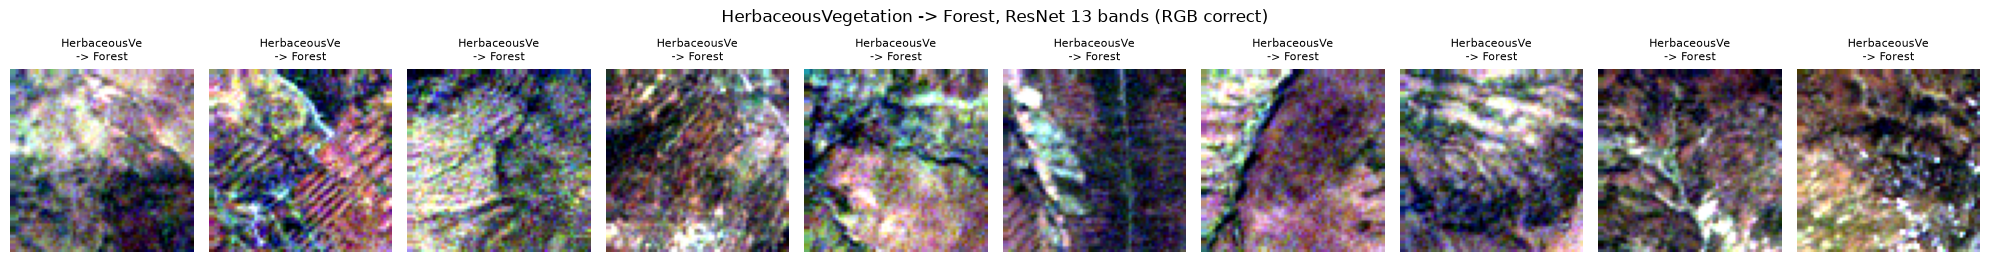

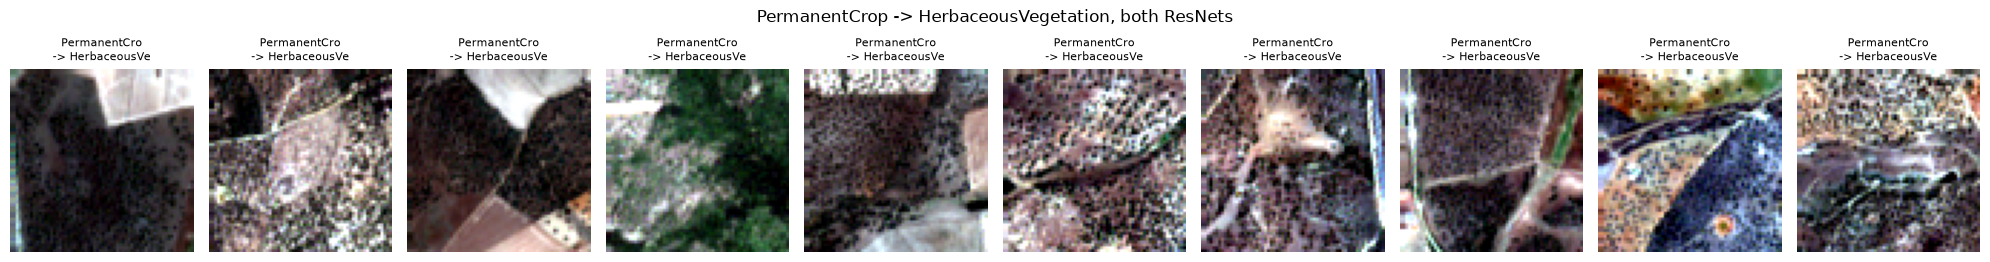

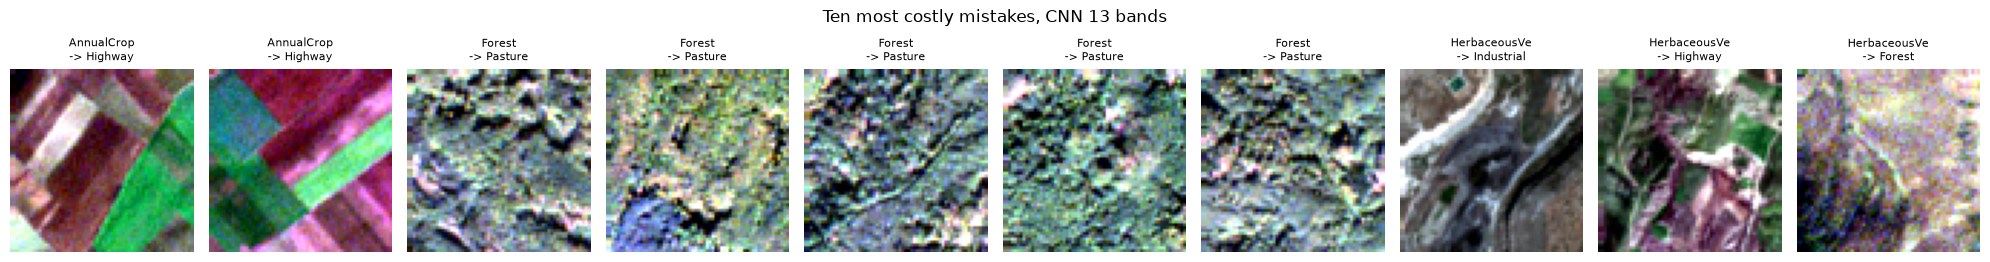

In [9]:
cache = get_cache(split, data_dir, project_root / "data" / "eurosat_cache.npy")
test_cache_rows = test_rows["cache_row"].to_numpy()
name_to_id = {name: k for k, name in enumerate(CLASS_NAMES)}


def show_patches(indices, title, predicted, n=10):
    """Show up to n test patches with their true and predicted class."""
    indices = list(indices)[:n]
    fig, axes = plt.subplots(1, n, figsize=(2 * n, 2.6))
    for ax in axes:
        ax.axis("off")
    for ax, k in zip(axes, indices):
        ax.imshow(to_rgb_image(np.asarray(cache[test_cache_rows[k]], dtype=np.float32)))
        ax.set_title(f"{CLASS_NAMES[y_true[k]][:12]}\n-> {CLASS_NAMES[predicted[k]][:12]}", fontsize=8)
    fig.suptitle(title, y=1.02)
    fig.tight_layout()
    return fig


resnet_rgb = predictions[("ResNet18", "rgb", 0)]["y_pred"].to_numpy()
resnet_13 = predictions[("ResNet18", "13band", 0)]["y_pred"].to_numpy()
cnn_13 = predictions[("SmallCNN", "13band", 0)]["y_pred"].to_numpy()
herb, forest, perm = name_to_id["HerbaceousVegetation"], name_to_id["Forest"], name_to_id["PermanentCrop"]

group1 = np.where((y_true == herb) & (resnet_13 == forest) & (resnet_rgb == herb))[0]
group2 = np.where((y_true == perm) & (resnet_13 == herb) & (resnet_rgb == herb))[0]
cnn_costs = costs[y_true, cnn_13]
group3 = np.argsort(-cnn_costs, kind="stable")[:10]
print("Group sizes (seed 0):", len(group1), len(group2), "and the ten costliest CNN mistakes")

for indices, title, predicted, name in ((group1, "HerbaceousVegetation -> Forest, ResNet 13 bands (RGB correct)", resnet_13, "herb_forest"),
                                         (group2, "PermanentCrop -> HerbaceousVegetation, both ResNets", resnet_13, "perm_herb"),
                                         (group3, "Ten most costly mistakes, CNN 13 bands", cnn_13, "cnn_costliest")):
    fig = show_patches(indices, title, predicted)
    fig.savefig(figures_dir / f"evaluation_errors_{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

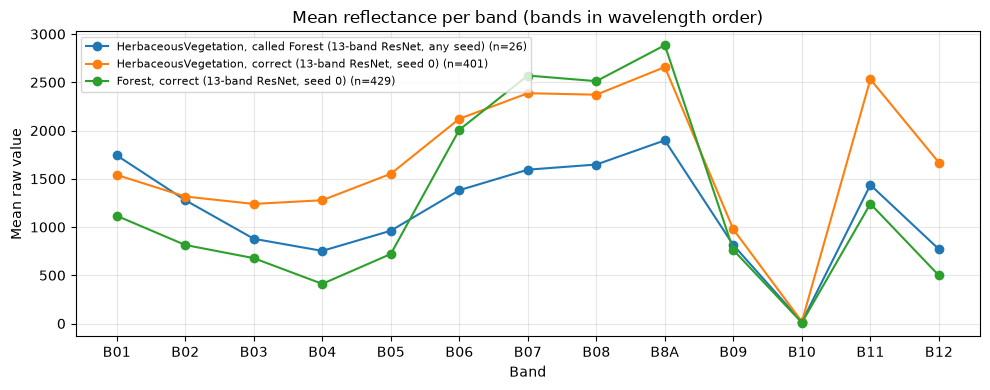

,B01,B02,B03,B04,B05,B06,B07,B08,B8A,B09,B10,B11,B12
"HerbaceousVegetation, called Forest (13-band ResNet, any seed)",1743.0,1279.0,878.0,753.0,962.0,1382.0,1595.0,1648.0,1898.0,813.0,16.0,1437.0,770.0
"HerbaceousVegetation, correct (13-band ResNet, seed 0)",1540.0,1316.0,1240.0,1278.0,1552.0,2121.0,2387.0,2372.0,2658.0,976.0,19.0,2531.0,1669.0
"Forest, correct (13-band ResNet, seed 0)",1117.0,814.0,678.0,411.0,720.0,2008.0,2570.0,2512.0,2884.0,762.0,10.0,1241.0,498.0


In [10]:
# hypothesis check: spectrum of the misclassified grassland against correct grassland and forest
def mean_spectrum(indices):
    return np.mean([np.asarray(cache[test_cache_rows[k]], dtype=np.float32).mean(axis=(1, 2)) for k in indices], axis=0)

all_seeds_herb_forest = sorted({k for s in SEEDS
                                for k in np.where((y_true == herb) & (predictions[("ResNet18", "13band", s)]["y_pred"].to_numpy() == forest))[0]})
groups = {"HerbaceousVegetation, called Forest (13-band ResNet, any seed)": all_seeds_herb_forest,
          "HerbaceousVegetation, correct (13-band ResNet, seed 0)": np.where((y_true == herb) & (resnet_13 == herb))[0],
          "Forest, correct (13-band ResNet, seed 0)": np.where((y_true == forest) & (resnet_13 == forest))[0]}

order = [BAND_NAMES.index(b) for b in ["B01", "B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "B09", "B10", "B11", "B12"]]
fig, ax = plt.subplots(figsize=(10, 4))
spectra = {}
for label, indices in groups.items():
    spectra[label] = mean_spectrum(indices)
    ax.plot([BAND_NAMES[b] for b in order], spectra[label][order], marker="o", label=f"{label} (n={len(indices)})")
ax.set(title="Mean reflectance per band (bands in wavelength order)", xlabel="Band", ylabel="Mean raw value")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(figures_dir / "evaluation_herb_forest_spectra.png", dpi=150, bbox_inches="tight")
plt.show()
display(pd.DataFrame(spectra, index=BAND_NAMES).T[[BAND_NAMES[b] for b in order]].round(0))

**Claim.** The hypothesis from notebook 05 is wrong: the grassland that the 13-band ResNet calls forest does not reflect near-infrared strongly. It is darker than typical grassland in almost every band, and in the short-wave infrared bands, which only the 13-band input has, it looks like forest.

**Evidence.**

- **The spectra.** The 26 HerbaceousVegetation patches called Forest by the 13-band ResNet (any seed) have a lower near-infrared value (B08: 1,648) than both correct grassland (2,372) and forest (2,512), so they do not look like forest there. They do look like forest in the red band (B04: 753, against 1,278 for grassland and 411 for forest) and in the short-wave infrared (B11: 1,437 against 2,531 and 1,241; B12: 770 against 1,669 and 498). They are higher than both in B01 (1,743), the band that is most sensitive to haze in the air.
- **The images, group 1.** The 12 patches (seed 0) that RGB gets right are mixed landscapes: open grassland with dark patches of shrubs or trees, field strips and tracks.
- **The images, group 2.** PermanentCrop called HerbaceousVegetation by both ResNets (42 patches at seed 0) shows trees or bushes as scattered dots on bare brown ground, sometimes beside a field. These look like orchards or olive groves with wide spacing, which from 10 m pixels resemble scrubland.
- **The images, group 3.** The costliest CNN mistakes include fields with straight edges called Highway, and open woodland called Pasture.

**Warrant.** A model can only separate classes that differ in what it sees. The extra bands make partly wooded grassland look more like forest, and widely spaced tree crops look like scrub with any input.

**Counterargument.** 26 patches is a small group, and we compared averages, not each patch. Many of these patches mix two land uses, so the label itself is uncertain. The higher B01 could mean these patches were imaged through more haze, which notebook 07 tests directly.

## 9. Sending uncertain patches to a human

The system is meant to flag parcels for human review, not to decide claims. The course's "reject option" leaves the cases where the model is least sure to a human expert, which lowers the error rate on the cases it does decide (Bishop, section 1.5.3, page 42). We sort the test patches of each run by the model's confidence (its highest class probability), send the least confident share to review, and measure how many of the critical errors that catches. The curve shows this for review budgets from 0% to 30% of the patches, and the table for 5%, 10% and 20%.

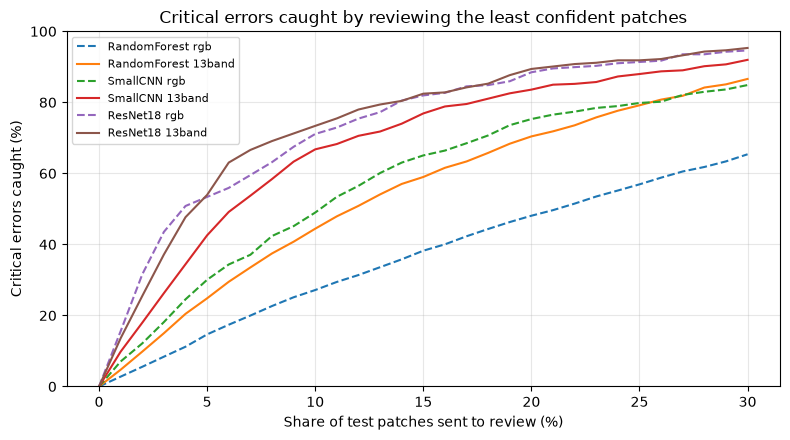

review_share          0.05   0.10   0.20
model        input                      
RandomForest rgb     0.147  0.272  0.481
             13band  0.248  0.444  0.704
SmallCNN     rgb     0.301  0.490  0.753
             13band  0.426  0.668  0.836
ResNet18     rgb     0.534  0.711  0.885
             13band  0.539  0.734  0.894

In [11]:
budgets = np.linspace(0, 0.30, 31)
review_rows = []
fig, ax = plt.subplots(figsize=(8, 4.5))
for model in MODELS:
    for input_type in INPUTS:
        caught = []
        for seed in SEEDS:
            table = predictions[(model, input_type, seed)]
            is_critical_error = critical[y_true, table["y_pred"].to_numpy()]
            order = np.argsort(table["confidence"].to_numpy(), kind="stable")  # least confident first
            caught_by_rank = np.cumsum(is_critical_error[order]) / max(1, is_critical_error.sum())
            caught.append([caught_by_rank[int(b * len(order)) - 1] if b > 0 else 0.0 for b in budgets])
        caught = np.mean(caught, axis=0)
        ax.plot(budgets * 100, caught * 100, ls="-" if input_type == "13band" else "--", label=f"{model} {input_type}")
        for budget in (0.05, 0.10, 0.20):
            review_rows.append({"model": model, "input": input_type, "review_share": budget,
                                "critical_errors_caught": caught[np.argmin(np.abs(budgets - budget))]})
ax.set(title="Critical errors caught by reviewing the least confident patches", xlabel="Share of test patches sent to review (%)",
       ylabel="Critical errors caught (%)", ylim=(0, 100))
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(figures_dir / "evaluation_review_curve.png", dpi=150, bbox_inches="tight")
plt.show()

review = pd.DataFrame(review_rows)
review.to_csv(results_dir / "evaluation_review.csv", index=False)
display(review.pivot_table(index=["model", "input"], columns="review_share", values="critical_errors_caught", sort=False).round(3))

**Claim.** Sending the least confident predictions to a human catches most critical mistakes at a small review cost, and the 13 bands make this work better for the random forest and the CNN.

**Evidence.** Reviewing the 10% least confident patches catches 71% (RGB) and 73% (13 bands) of the ResNet's critical mistakes, 49% and 67% for the CNN, and 27% and 44% for the random forest. At 20% review, the ResNet catches 89% of them.

**Warrant.** The reject option lowers the error rate on the cases the system decides by leaving the uncertain cases to an expert (Bishop, section 1.5.3, page 42). For an insurer, this is the proposal's use: the model flags parcels for review, and a human decides.

**Counterargument.** The confidence of a random forest (the share of trees voting for a class) and that of a network (a softmax probability) are not on the same scale, so the curves compare how well each model ranks its own mistakes, not one common threshold. The review share also depends on the cost of a human check, which we do not know.

## Summary

- **SQ1.** The 13-band advantage holds for the random forest (accuracy +15.8 points) and the CNN (+3.6 points), with block-bootstrap intervals that exclude 0. For the pretrained ResNet there is no difference (-0.01 points, interval -0.7 to +0.6).
- **SQ2.** The costly mistakes are concentrated in a few pairs: PermanentCrop and HerbaceousVegetation confused with each other, PermanentCrop called AnnualCrop and HerbaceousVegetation called Forest. As models get better, critical mistakes become a larger share of the remaining mistakes (55% for the RGB random forest, 85% for the RGB ResNet).
- **SQ3.** The 13 bands reduce critical mistakes and cost for the random forest (critical-error rate 16.4% to 9.7%) and the CNN (5.0% to 3.5%), but not for the ResNet (2.4% against 2.5%), where fewer grassland-to-permanent-crop mistakes are offset by more grassland-to-forest mistakes.
- These conclusions hold under all five cost assumptions, including the earlier list of critical confusions.
- The grassland called forest is darker than typical grassland and forest-like in the short-wave infrared, not in the near-infrared. Many of the remaining mistakes are mixed patches.
- Reviewing the 10% least confident patches catches 71 to 73% of the ResNet's critical mistakes.
- For an insurer, the pretrained ResNet is the best model, and with it RGB is as good as 13 bands. The extra bands only pay off for models that do not start from ImageNet features.

## References

Course: AI, Machine Learning & Analytics, IE University, fall 2026 (Prof. P. Delgado-Santos). Course files are cited by file name with the slide, page or section used.

**Course material**

- `lecture_2_introduction_to_ML.pdf`, lecture slides. Used: slides 24, 34 and 35.
- `ImageClassificationML.pdf`, course notebook. Used: page 15.
- Bishop, C. M. (2006). *Pattern Recognition and Machine Learning*. Springer. Course textbook. Used: section 1.5.2, page 41 and section 1.5.3, page 42.
- Piece of Crop (2026). Group project proposal. Used: known issue 3 and intended use.

**External sources**

- Helber, P., Bischke, B., Dengel, A. & Borth, D. (2019). EuroSAT: A novel dataset and deep learning benchmark for land use and land cover classification. *IEEE Journal of Selected Topics in Applied Earth Observations and Remote Sensing*, 12(7), 2217–2226. https://doi.org/10.1109/JSTARS.2019.2918242. Used for: the dataset.
- He, K., Zhang, X., Ren, S. & Sun, J. (2016). Deep residual learning for image recognition. *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (CVPR)*, 770–778. Used for: ResNet18 predictions evaluated.
- Efron, B. & Tibshirani, R. J. (1993). *An Introduction to the Bootstrap*. Chapman & Hall. Used for: block bootstrap, chapters 6 and 13.
- Field, C. A. & Welsh, A. H. (2007). Bootstrapping clustered data. *Journal of the Royal Statistical Society: Series B*, 69(3), 369–390. https://doi.org/10.1111/j.1467-9868.2007.00593.x. Used for: bootstrapping clustered data.